In [42]:
import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

# Import dari GLayout
from glayout import gf180, sky130
from glayout.primitives.fet import nmos, pmos
from glayout.primitives.mimcap import mimcap
from glayout.primitives.guardring import tapring
from glayout.cells.elementary.diff_pair.diff_pair import diff_pair
from glayout.cells.composite.differential_to_single_ended_converter.differential_to_single_ended_converter import differential_to_single_ended_converter
from glayout.cells.composite.opamp.opamp import opamp
from glayout.util.comp_utils import evaluate_bbox
from glayout.primitives.via_gen import via_stack
from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route
from glayout.routing.L_route import L_route
from gdsfactory import Component
from gdsfactory.components import rectangle
from glayout.util.comp_utils import evaluate_bbox, prec_center, prec_ref_center, align_comp_to_port
from gdsfactory import Port
import numpy as np

# Fungsi display
hide = widgets.Output()


def display_gds(gds_file, scale=3):
    top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
    top_level_cell.write_svg('out.svg')
    fig = sg.fromfile('out.svg')
    fig.set_size((str(float(fig.width) * scale),
                 str(float(fig.height) * scale)))
    fig.save('out.svg')
    IPython.display.display(IPython.display.SVG('out.svg'))


def display_component(component, scale=3):
    with hide:
        component.write_gds("out.gds")
    display_gds('out.gds', scale)


# Aktifkan PDK (gf180)
pdk = gf180

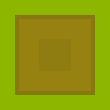

In [43]:
via_example = via_stack(pdk, glayer1='met1', glayer2='met2')
display_component(via_example, scale=20)

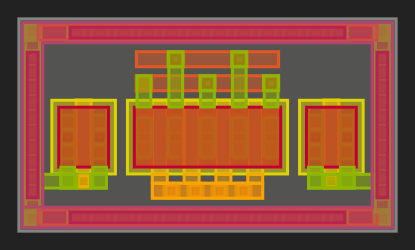

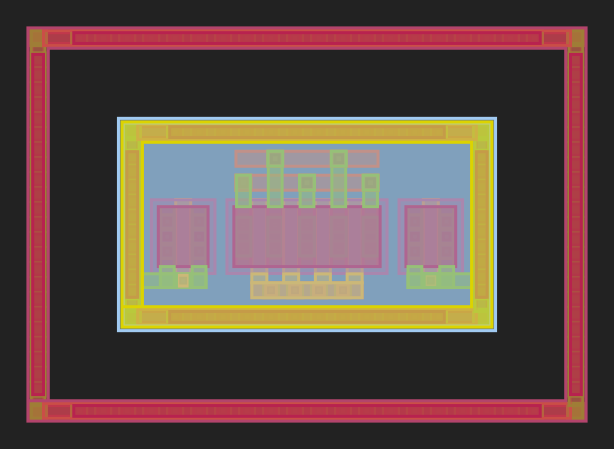

In [44]:
nmos_inst = nmos(pdk, width=2, length=0.5, fingers=4, with_dnwell=False, with_substrate_tap=False)
display_component(nmos_inst, scale=3)

pmos_inst = pmos(pdk, width=2, length=0.5, fingers=4)
display_component(pmos_inst, scale=3)

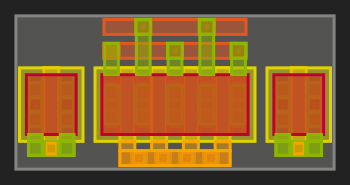

In [45]:
nmos_inst = nmos(pdk, width=2, length=0.5, fingers=4,
                 with_dnwell=False, with_substrate_tap=False, with_tie=False)
display_component(nmos_inst, scale=3)

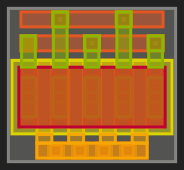

In [46]:
nmos_inst = nmos(pdk, width=2, length=0.5, fingers=4,
                 with_dnwell=False, with_substrate_tap=False, with_tie=False, with_dummy=False)
display_component(nmos_inst, scale=3)

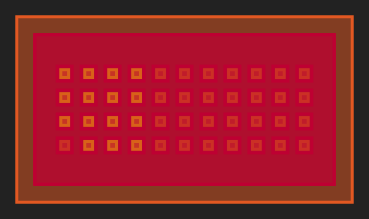

In [47]:
cap = mimcap(pdk, size=[10.0, 5.0])
display_component(cap, scale=3)

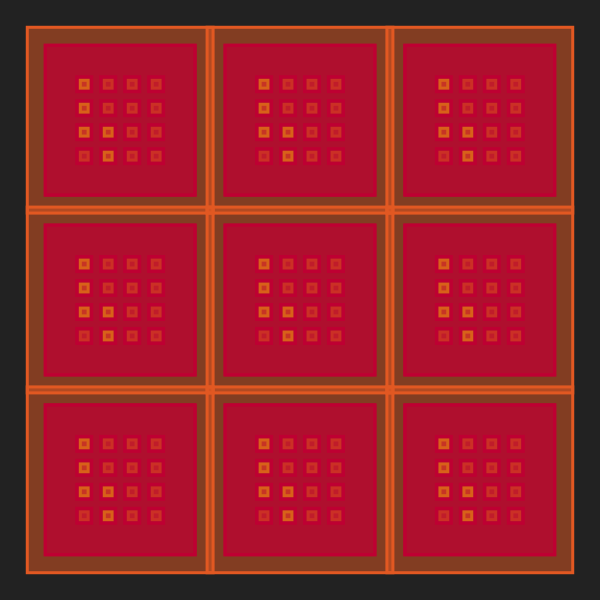

In [48]:
def capacitor_array(pdk, rows=2, cols=2, cap_size=[5.0, 5.0], spacing=1.0):
    comp = Component(name="cap_array")
    for r in range(rows):
        for c in range(cols):
            cap_inst = comp << mimcap(pdk, size=cap_size)
            cap_inst.move((c*(cap_size[0]+spacing), r*(cap_size[1]+spacing)))
    return comp


cap_array = capacitor_array(pdk, rows=3, cols=3)
display_component(cap_array, scale=3)

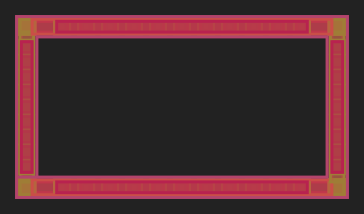

In [49]:
guard = tapring(pdk, enclosed_rectangle=[10.0, 5.0])
display_component(guard, scale=3)

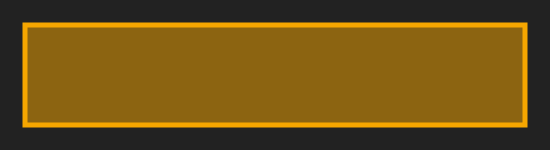

In [50]:
def resistor(pdk, length=10.0, width=1.0, layer='poly'):
    """Membuat resistor dengan panjang dan lebar tertentu."""
    glayer = pdk.get_glayer(layer)  # misal 'poly' atau 'diff'
    comp = Component(name="resistor")
    # Asumsikan resistor berupa persegi panjang
    comp << rectangle(size=(length, width), layer=glayer)
    # Tambahkan port di ujung-ujungnya (opsional)
    return comp

res = resistor(pdk, length=10, width=2)
display_component(res, scale=5)

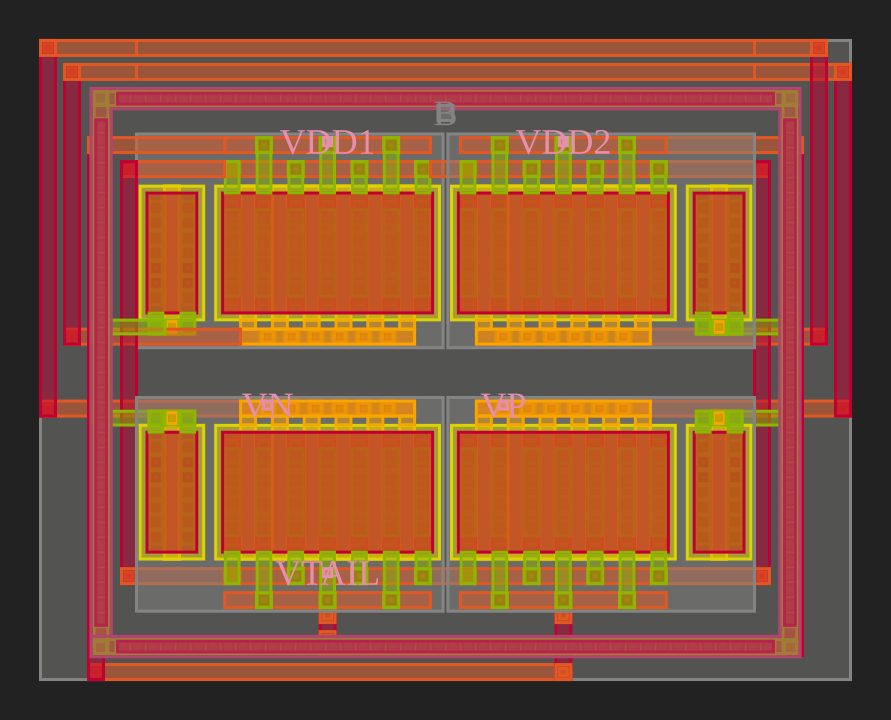

In [51]:
dp_cc = diff_pair(pdk, width=4, length=0.5, fingers=6,
                  n_or_p_fet=True)  # True untuk NMOS
display_component(dp_cc, scale=3)

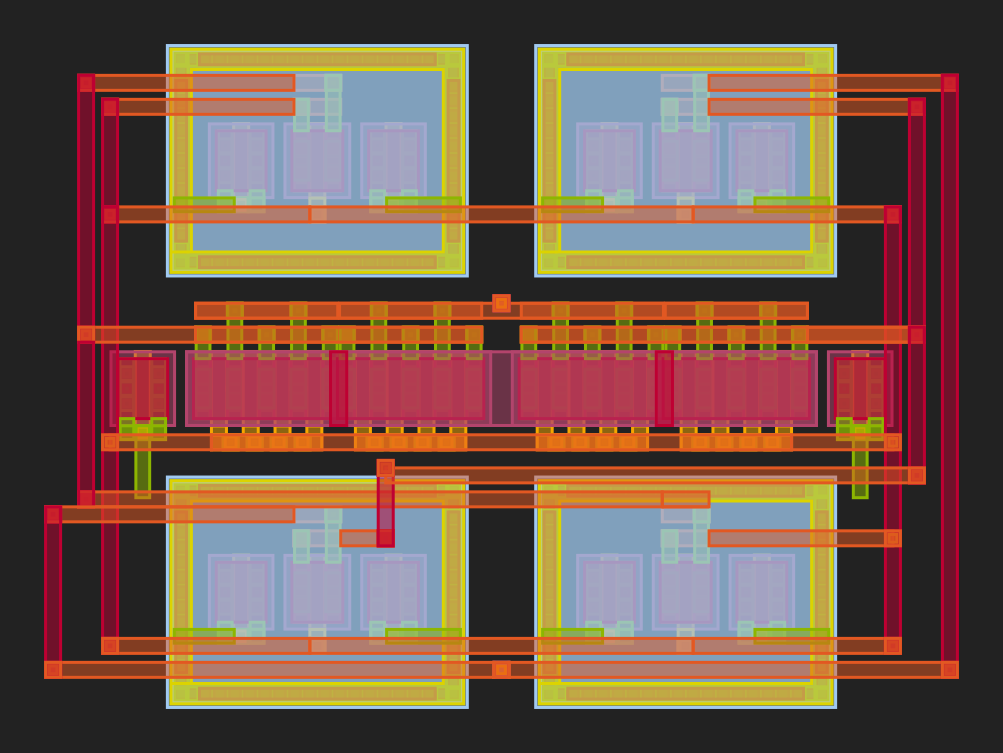

In [52]:
d2s = differential_to_single_ended_converter(
    pdk, rmult=1, half_pload=[2, 0.5, 1], via_xlocation=0)
display_component(d2s, scale=3)

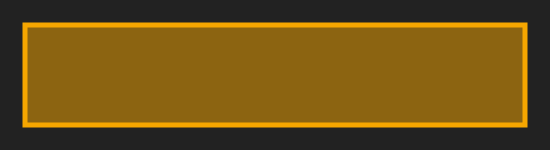

In [53]:
def resistor(pdk, length=10.0, width=1.0, layer='poly'):
    """Resistor dengan port di kiri dan kanan."""
    comp = Component(name="resistor")
    glayer = pdk.get_glayer(layer)
    rect = comp << rectangle(size=(length, width), layer=glayer)
    # Tambahkan port (pusat di ujung kiri/kanan) - Port harus memiliki name
    port_e = Port(name='E', center=(0, width/2),
                  width=width, orientation=180, layer=glayer)
    port_w = Port(name='W', center=(length, width/2),
                  width=width, orientation=0, layer=glayer)
    comp.add_port(name='E', port=port_e)
    comp.add_port(name='W', port=port_w)
    return comp


res = resistor(pdk, length=10, width=2)
display_component(res, scale=5)

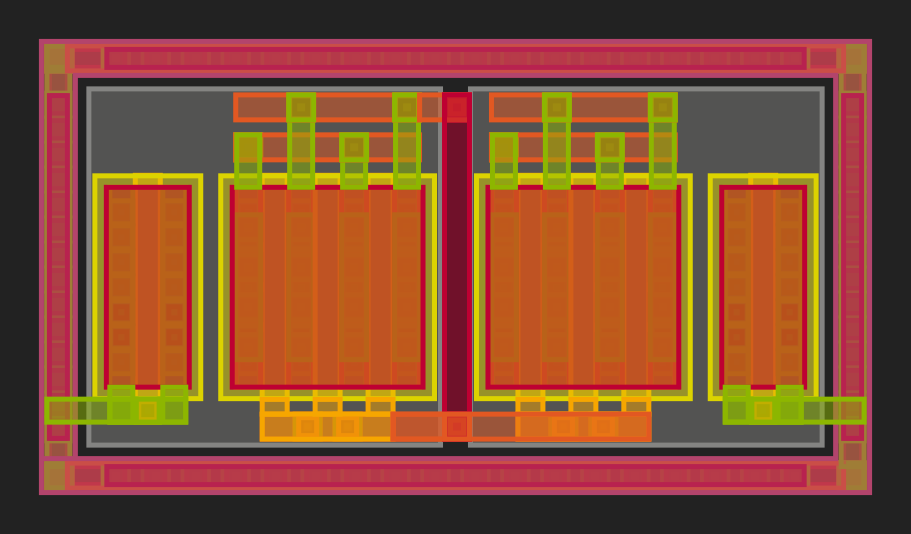

In [54]:
def simple_current_mirror(pdk):
    comp = Component(name="simple_cmirror")
    # Transistor referensi (NMOS)
    ref = nmos(pdk, width=4, length=0.5, fingers=3, with_dnwell=False, with_substrate_tap=False, with_tie=False, with_dummy=(True, False))
    # Transistor mirror (NMOS)
    mir = nmos(pdk, width=4, length=0.5, fingers=3, with_dnwell=False, with_substrate_tap=False, with_tie=False, with_dummy=(False, True))

    ref_inst = comp << ref
    mir_inst = comp << mir
    # Tempatkan mirror di kanan ref dengan spacing
    spacing = pdk.util_max_metal_seperation()
    mir_inst.movex(evaluate_bbox(ref)[0] + 2*spacing)

    # Hubungkan gate keduanya (straight route)
    route_gate = straight_route(
        pdk, ref_inst.ports["gate_E"], mir_inst.ports["gate_E"])
    comp << route_gate

    # Hubungkan drain ref ke gate (diode-connected) menggunakan c_route
    route_diode = c_route(
        pdk, ref_inst.ports["drain_E"], ref_inst.ports["gate_E"])
    comp << route_diode

    tap_ring = tapring(pdk, enclosed_rectangle=evaluate_bbox(
    comp.flatten(),
    padding=pdk.get_grule("nwell", "active_diff")["min_enclosure"]))
    shift_amount = -prec_center(comp.flatten())[0]
    tring_ref = comp << tap_ring
    tring_ref.movex(destination=shift_amount)

    # Route dummy to tapring (We have to route it manually since we generated the tapring manually)
    comp << straight_route(pdk, ref_inst.ports["multiplier_0_dummy_L_gsdcon_top_met_E"],
                              tring_ref.ports["W_top_met_W"])
    comp << straight_route(pdk, mir_inst.ports["multiplier_0_dummy_R_gsdcon_top_met_W"],
                              tring_ref.ports["E_top_met_E"])

    return comp


cm = simple_current_mirror(pdk)
display_component(cm, scale=5)

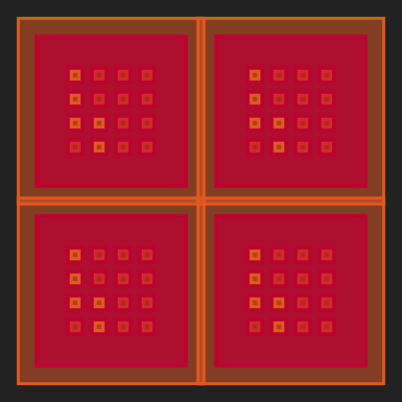

In [55]:
def capacitor_array(pdk, rows=2, cols=2, cap_size=[5.0, 5.0], spacing=1.0):
    comp = Component(name="cap_array")
    cap_unit = mimcap(pdk, size=cap_size)
    instances = []
    for r in range(rows):
        for c in range(cols):
            inst = comp << cap_unit
            inst.move((c*(cap_size[0]+spacing), r*(cap_size[1]+spacing)))
            instances.append(inst)
    # Routing paralel: hubungkan semua kapasitor secara paralel dengan metal
    # Ambil port dari kapasitor pertama
    if instances and 'p1' in instances[0].ports:
        # Buat bus metal untuk menghubungkan semua kapasitor
        # Ini hanya contoh, kita tambahkan via dan routing sederhana
        # Kita gunakan straight_route untuk menghubungkan p1 ke p1, n1 ke n1
        for i in range(1, len(instances)):
            route_p = straight_route(
                pdk, instances[0].ports['p1'], instances[i].ports['p1'])
            comp << route_p
            route_n = straight_route(
                pdk, instances[0].ports['n1'], instances[i].ports['n1'])
            comp << route_n
        # Ekspos port dari kapasitor pertama sebagai port array
        comp.add_port(name='pos', port=instances[0].ports['p1'])
        comp.add_port(name='neg', port=instances[0].ports['n1'])
    return comp


cap_array = capacitor_array(pdk, rows=2, cols=2)
display_component(cap_array, scale=3)

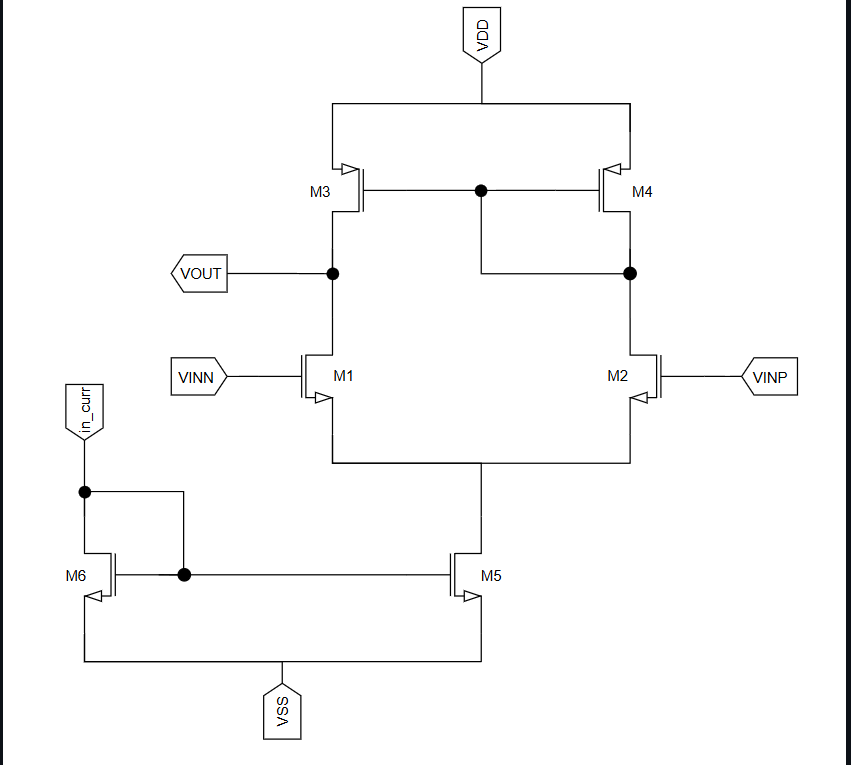

In [56]:
nmos_kwargs = {
    "with_tie": False,                        # add tie layer for bulk connection
    "with_dnwell": False,                     # deep n-well for substrate isolation
    # top metal layer for source/drain routing
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",              # top metal layer for gate routing
    "sd_route_left": True,                    # route source/drain to the left
    # metal width multiplier for source/drain (None = default)
    "rmult": None,
    "gate_rmult": 1,                          # metal width multiplier for gate
    "interfinger_rmult": 1,                   # metal width multiplier between fingers
    "substrate_tap_layers": ("met2", "met1"),  # layers for substrate tap
    "dummy_routes": True                      # add routing to dummy fets
}

pmos_kwargs = {
    "with_tie": False,
    "dnwell": False,
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",
    "sd_route_left": True,
    "rmult": None,
    "gate_rmult": 1,
    "interfinger_rmult": 1,
    "substrate_tap_layers": ("met2", "met1"),
    "dummy_routes": True
}

config = {
    "pdk": gf180,

    # Differential Input Pair (M1, M2) — NMOS
    "input_pair": {
        "width": 5.75,
        "length": 0.4,
        "fingers": 2,
        "multipliers": 1,
        "device_type": "nmos",
    },

    # Current Mirror Load (M3, M4) — PMOS
    "current_mirror": {
        "width": 8.45,
        "length": 0.4,
        "fingers": 5,
        "multipliers": 1,
        "device_type": "pmos",
    },

    # Tail Current Source (M5) — NMOS
    "tail_source": {
        "width": 9.55,
        "length": 0.7,
        "fingers": 5,
        "multipliers": 1,
        "device_type": "nmos",
    },

    # Layout and routing rules
    "layout_rules": {
        "spacing": 2.0,
        "routing_metal": "met2",
        "dummy_devices": True,
        "tie_layers": ("met2", "met1"),   # tapring metal layers
        "sd_rmult": 1,                    # source/drain metal width multiplier
    }
}


def current_mirror(pdk, config):
    cm_comp = Component(name="current_mirror")

    # Extract parameters from config
    width = config["current_mirror"]["width"]
    length = config["current_mirror"]["length"]
    fingers = config["current_mirror"]["fingers"]
    multipliers = config["current_mirror"]["multipliers"]
    tie_layers = config["layout_rules"]["tie_layers"]
    sd_rmult = config["layout_rules"]["sd_rmult"]

    # Instantiate two PMOS transistors
    pfet_m4 = pmos(pdk, width=width, length=length, fingers=fingers,
                   multipliers=multipliers,
                   with_substrate_tap=False,
                   with_dummy=(False, True),
                   tie_layers=tie_layers,
                   sd_rmult=sd_rmult,
                   **pmos_kwargs)

    pfet_m3 = pmos(pdk, width=width, length=length, fingers=fingers,
                   multipliers=multipliers,
                   with_substrate_tap=False,
                   with_dummy=(True, False),
                   tie_layers=tie_layers,
                   sd_rmult=sd_rmult,
                   **pmos_kwargs)

    cm4_ref = cm_comp << pfet_m4
    cm3_ref = cm_comp << pfet_m3
    cm4_ref.name = "pfet_m4"
    cm3_ref.name = "pfet_m3"

    # Placement: move pfet_m4 to the right of pfet_m3
    cm4_ref.movex(evaluate_bbox(pfet_m3)[0] + pdk.util_max_metal_seperation())

    # Tapring enclosure
    tap_ring = tapring(pdk,
                       enclosed_rectangle=evaluate_bbox(
                           cm_comp.flatten(),
                           padding=pdk.get_grule("nwell", "active_diff")["min_enclosure"]),
                       sdlayer="n+s/d",
                       horizontal_glayer=tie_layers[0],
                       vertical_glayer=tie_layers[1])
    shift_amount = -prec_center(cm_comp.flatten())[0]
    tring_ref = cm_comp << tap_ring
    tring_ref.movex(destination=shift_amount)

    # nwell padding to merge the two separate nwell regions
    cm_comp.add_padding(layers=(pdk.get_glayer("nwell"),), default=1)

    # Internal routing
    cm_comp << straight_route(pdk, cm4_ref.ports["multiplier_0_source_E"],
                              cm3_ref.ports["multiplier_0_source_E"])
    cm_comp << straight_route(pdk, cm4_ref.ports["multiplier_0_gate_E"],
                              cm3_ref.ports["multiplier_0_gate_E"])
    cm_comp << c_route(pdk, cm4_ref.ports["multiplier_0_gate_E"], 
                       cm4_ref.ports["multiplier_0_drain_E"])

    # Route dummy to tapring (We have to route it manually since we generated the tapring manually)
    cm_comp << straight_route(pdk, cm3_ref.ports["multiplier_0_dummy_L_gsdcon_top_met_E"],
                              tring_ref.ports["W_top_met_W"])
    cm_comp << straight_route(pdk, cm4_ref.ports["multiplier_0_dummy_R_gsdcon_top_met_W"],
                              tring_ref.ports["E_top_met_E"])

    # Expose ports
    cm_comp.add_ports(cm4_ref.get_ports_list(), prefix="M4_")
    cm_comp.add_ports(cm3_ref.get_ports_list(), prefix="M3_")
    cm_comp.add_ports(tring_ref.get_ports_list(), prefix="TRING_")

    return cm_comp

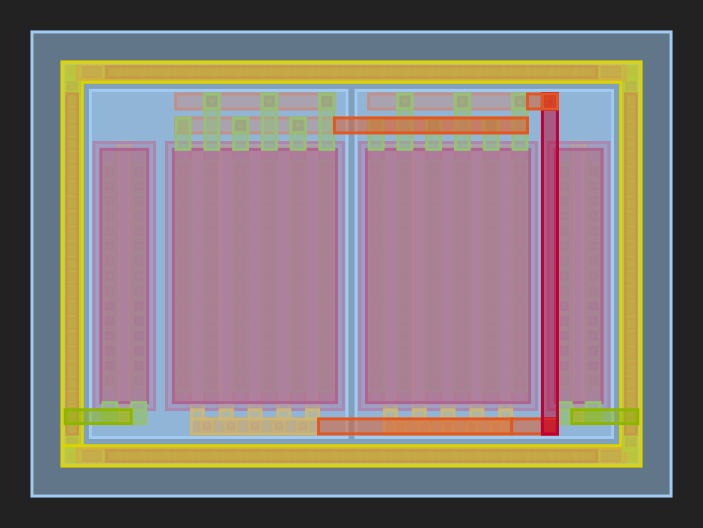

In [57]:
top_level = Component(name="current_mirror")
pdk = config["pdk"]

cm = current_mirror(pdk, config)
cm_ref = top_level << cm
cm_ref.name = "current_mirror"

display_component(top_level, scale=3)
# top_level.show()

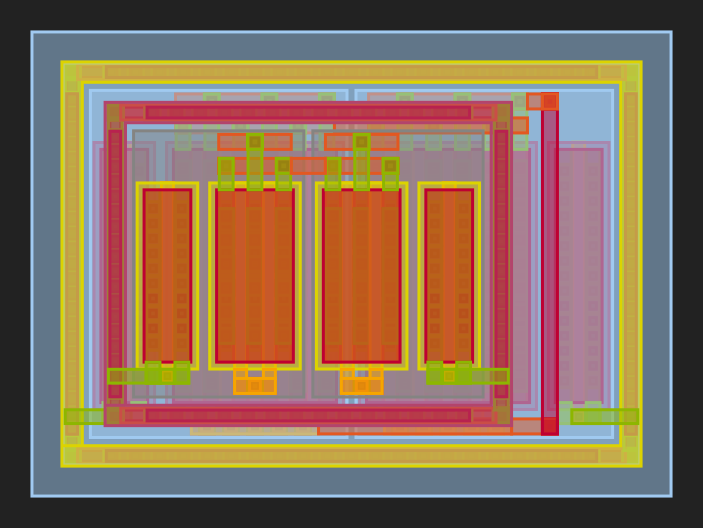

In [58]:
def diff_pair(pdk, config):
    dp_comp = Component(name="diff_pair")

    # Extract parameters from config
    width = config["input_pair"]["width"]
    length = config["input_pair"]["length"]
    fingers = config["input_pair"]["fingers"]
    multipliers = config["input_pair"]["multipliers"]
    tie_layers = config["layout_rules"]["tie_layers"]
    sd_rmult = config["layout_rules"]["sd_rmult"]

    # Instantiate two NMOS transistors
    m1 = nmos(pdk, width=width, length=length, fingers=fingers,
              multipliers=multipliers,
              with_substrate_tap=False,
              with_dummy=(True, False),
              tie_layers=tie_layers,
              sd_rmult=sd_rmult,
              **nmos_kwargs)
    m2 = nmos(pdk, width=width, length=length, fingers=fingers,
              multipliers=multipliers,
              with_substrate_tap=False,
              with_dummy=(False, True),
              tie_layers=tie_layers,
              sd_rmult=sd_rmult,
              **nmos_kwargs)

    m1_ref = dp_comp << m1
    m2_ref = dp_comp << m2
    m1_ref.name = "M1"  # negative input
    m2_ref.name = "M2"  # positive input

    # Placement
    ref_dimensions = evaluate_bbox(m1)
    m2_ref.movex(m1_ref.xmax)
    m2_ref.movex(ref_dimensions[0] / 2)
    m2_ref.movex(pdk.util_max_metal_seperation())

    # Connect sources together
    dp_comp << straight_route(pdk,
                              m1_ref.ports["multiplier_0_source_E"],
                              m2_ref.ports["multiplier_0_source_W"])

    # Tapring enclosure
    tap_ring = tapring(pdk, enclosed_rectangle=evaluate_bbox(
        dp_comp.flatten(),
        padding=pdk.get_grule("nwell", "active_diff")["min_enclosure"]))
    shift_amount = -prec_center(dp_comp.flatten())[0]
    tring_ref = dp_comp << tap_ring
    tring_ref.movex(destination=shift_amount)

    # Route dummy to tapring (We have to route it manually since we generated the tapring manually)
    dp_comp << straight_route(pdk, m1_ref.ports["multiplier_0_dummy_L_gsdcon_top_met_E"],
                              tring_ref.ports["W_top_met_W"])
    dp_comp << straight_route(pdk, m2_ref.ports["multiplier_0_dummy_R_gsdcon_top_met_W"],
                              tring_ref.ports["E_top_met_E"])

    # Expose ports
    dp_comp.add_ports(m1_ref.get_ports_list(), prefix="M1_")
    dp_comp.add_ports(m2_ref.get_ports_list(), prefix="M2_")
    dp_comp.add_ports(tring_ref.get_ports_list(), prefix="TRING_")

    return dp_comp


dp = diff_pair(pdk, config)
dp_ref = top_level << dp
dp_ref.name = "diff_pair_2"

display_component(top_level, scale=3)

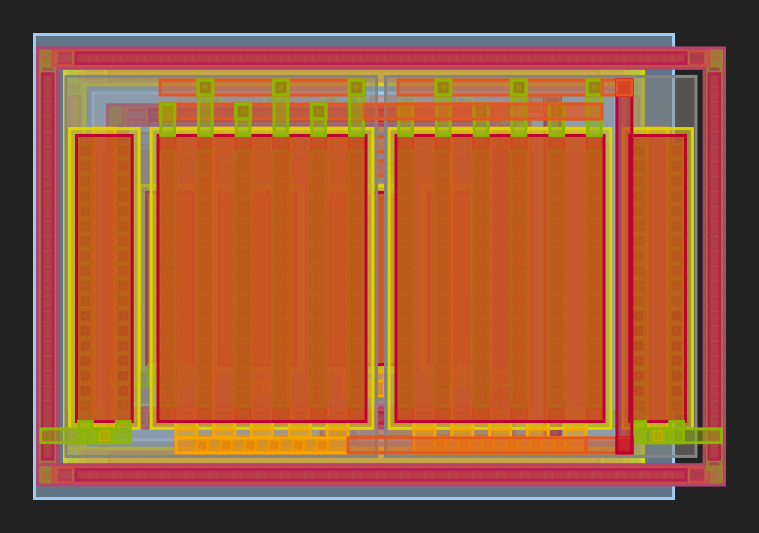

In [59]:
def tail_current(pdk, config):
    tail_comp = Component(name="tail_current")

    # Extract parameters from config
    width = config["tail_source"]["width"]
    length = config["tail_source"]["length"]
    fingers = config["tail_source"]["fingers"]
    multipliers = config["tail_source"]["multipliers"]
    tie_layers = config["layout_rules"]["tie_layers"]
    sd_rmult = config["layout_rules"]["sd_rmult"]

    # Instantiate two NMOS transistors
    nfet_m6 = nmos(pdk, width=width, length=length, fingers=fingers,
                   multipliers=multipliers,
                   with_substrate_tap=False,
                   with_dummy=(False, True),
                   tie_layers=tie_layers,
                   sd_rmult=sd_rmult,
                   **nmos_kwargs)

    nfet_m5 = nmos(pdk, width=width, length=length, fingers=fingers,
                   multipliers=multipliers,
                   with_substrate_tap=False,
                   with_dummy=(True, False),
                   tie_layers=tie_layers,
                   sd_rmult=sd_rmult,
                   **nmos_kwargs)

    m6 = tail_comp << nfet_m6
    m5 = tail_comp << nfet_m5
    m6.name = "nfet_m6"
    m5.name = "nfet_m5"

    # Placement
    m6.movex(evaluate_bbox(nfet_m5)[0] + pdk.util_max_metal_seperation())

    # Tapring enclosure
    tap_ring = tapring(pdk, enclosed_rectangle=evaluate_bbox(
        tail_comp.flatten(),
        padding=pdk.get_grule("nwell", "active_diff")["min_enclosure"]))
    shift_amount = -prec_center(tail_comp.flatten())[0]
    tring_ref = tail_comp << tap_ring
    tring_ref.movex(destination=shift_amount)

    # Internal routing
    tail_comp << straight_route(pdk, m6.ports["multiplier_0_source_E"],
                                m5.ports["multiplier_0_source_E"])
    tail_comp << straight_route(pdk, m6.ports["multiplier_0_gate_E"],
                                m5.ports["multiplier_0_gate_E"])
    tail_comp << c_route(pdk, m6.ports["multiplier_0_gate_E"],
                         m6.ports["multiplier_0_drain_E"])

    # Route dummy to tapring (We have to route it manually since we generated the tapring manually)
    tail_comp << straight_route(pdk, m5.ports["multiplier_0_dummy_L_gsdcon_top_met_E"],
                                tring_ref.ports["W_top_met_W"])
    tail_comp << straight_route(pdk, m6.ports["multiplier_0_dummy_R_gsdcon_top_met_W"],
                                tring_ref.ports["E_top_met_E"])

    # Expose ports
    tail_comp.add_ports(m6.get_ports_list(), prefix="M6_")
    tail_comp.add_ports(m5.get_ports_list(), prefix="M5_")
    tail_comp.add_ports(tring_ref.get_ports_list(), prefix="TRING_")
    return tail_comp


tail = tail_current(pdk, config)
tail_ref = top_level << tail
tail_ref.name = "tail_current"

display_component(top_level, scale=3)

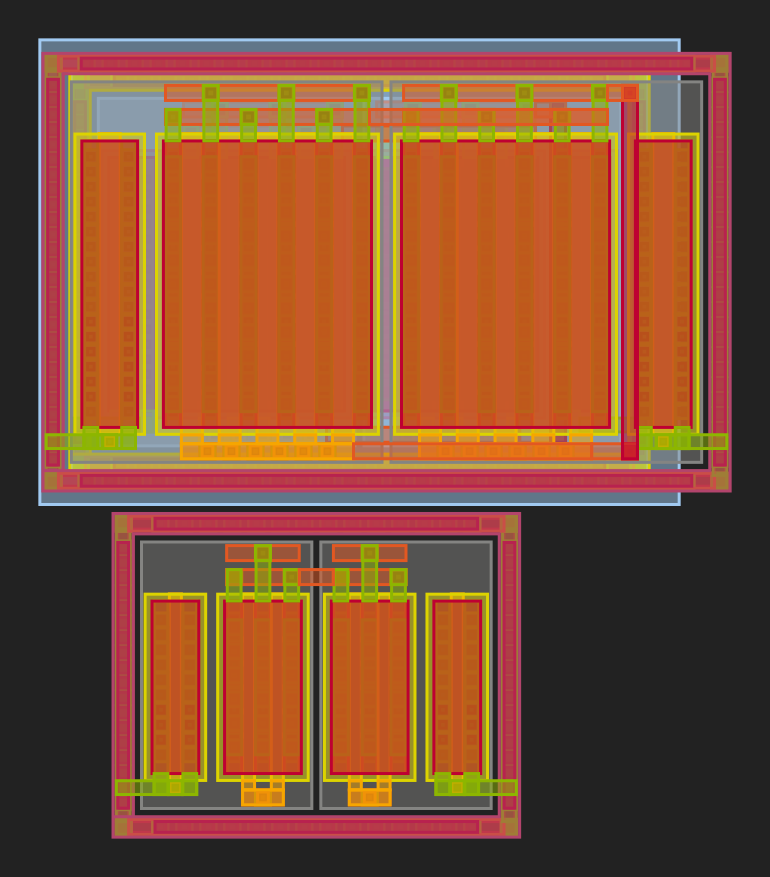

In [60]:
dp_dimensions = evaluate_bbox(dp)
tail_dimensions = evaluate_bbox(tail)
cm_dimensions = evaluate_bbox(cm)

# Place diff_pair below current_mirror
dp_ref.movey(cm_ref.ymin - dp_dimensions[1] /
             2 - pdk.util_max_metal_seperation())

display_component(top_level, scale=3)

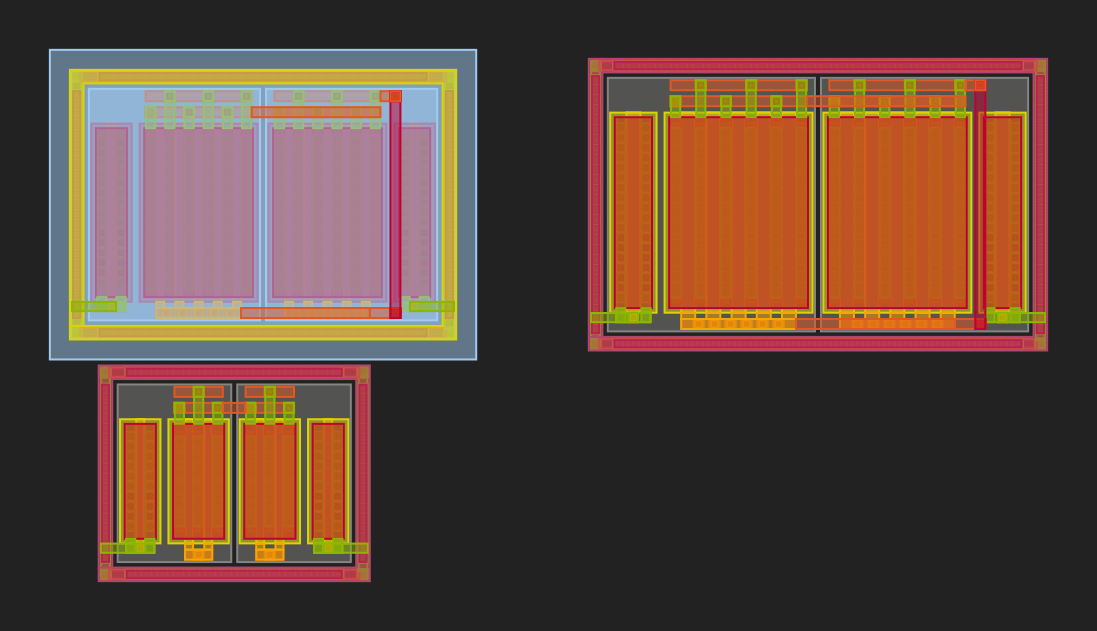

In [61]:
# Place tail_current right of current_mirror
tail_ref.movex(
    cm_ref.xmax + tail_dimensions[0]/2 + pdk.util_max_metal_seperation())

display_component(top_level, scale=2)